In [ ]:
!pip install --upgrade --no-cache-dir "scikit-learn>=1.6" "scipy>=1.14" -q

In [ ]:
import numpy as np
print("numpy:", np.__version__)
np.random.RandomState(0)

import sklearn
print("sklearn:", sklearn.__version__)

import scipy
print("scipy:", scipy.__version__)

numpy: 2.1.3
sklearn: 1.9.0
scipy: 1.18.1


In [ ]:
from google.colab import files
import zipfile, os

uploaded = files.upload()  # choose calamba-chatbot.zip

zip_name = list(uploaded.keys())[0]
with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall('/content')

os.chdir('/content/calamba_chatbot')
print("Working directory:", os.getcwd())

Saving calamba_chatbot.zip to calamba_chatbot (4).zip
Working directory: /content/calamba_chatbot


In [ ]:
!apt-get update -qq && apt-get install -y zstd

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
zstd is already the newest version (1.4.8+dfsg-3build1).
0 upgraded, 0 newly installed, 0 to remove and 78 not upgraded.


In [ ]:
!curl -fsSL https://ollama.com/install.sh | sh

>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [ ]:
import subprocess, time

ollama_process = subprocess.Popen(
    ["ollama", "serve"],
    stdout=open("/content/ollama.log", "a"),
    stderr=subprocess.STDOUT,
)
time.sleep(5)
print("Ollama server starting (PID:", ollama_process.pid, ")")

Ollama server starting (PID: 31492 )


In [ ]:
!ollama pull qwen2.5:7b-instruct

In [ ]:
!sed -i 's/requests==2.32.3/requests>=2.32.4/' requirements.txt
!pip install -q -r requirements.txt

In [ ]:
import chromadb
from backend.config import CHROMA_PERSIST_DIR, CHROMA_COLLECTION_NAME
client = chromadb.PersistentClient(path=CHROMA_PERSIST_DIR)

ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given


In [ ]:
!python -m backend.build_index

2026-08-25 03:21:40.254203: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Loaded 206 documents -> 251 chunks.
Embedding and indexing into ChromaDB...
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientCreateCollectionEvent: capture() takes 1 positional argument but 3 were given
Embedding 251 chunks with all-MiniLM-L6-v2 ...
Batches: 100% 8/8 [00:01<00:00,  7.89it/s]
Done. Index is ready for queries.


In [ ]:
from backend.embeddings import get_chroma_collection
print(get_chroma_collection().count())

ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientCreateCollectionEvent: capture() takes 1 positional argument but 3 were given


251


In [ ]:
!python -m backend.intent_classifier

Train accuracy: 0.946 | Test accuracy: 0.909


In [ ]:
import numpy as np
print(np.__version__)

2.1.3


In [ ]:
!pip show chromadb sentence-transformers | grep -i requires

Requires: bcrypt, build, chroma-hnswlib, fastapi, grpcio, httpx, importlib-resources, kubernetes, mmh3, numpy, onnxruntime, opentelemetry-api, opentelemetry-exporter-otlp-proto-grpc, opentelemetry-instrumentation-fastapi, opentelemetry-sdk, orjson, overrides, posthog, pydantic, pypika, PyYAML, rich, tenacity, tokenizers, tqdm, typer, typing_extensions, uvicorn
Requires: huggingface-hub, Pillow, scikit-learn, scipy, torch, tqdm, transformers


In [ ]:
from backend.intent_classifier import train_and_save

train_and_save()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Train accuracy: 0.946 | Test accuracy: 0.909


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('embed', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](13,)","['AGRICULTURAL','BUSINESS_TRADE','CERTIFICATES_PERMITS_IDS',..., 'SOCIAL_SERVICES','TAX','VETERINARY']"
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_rat

In [ ]:
from backend.rag_pipeline import answer_question

history = []
result = answer_question("What are the requirements for a business permit?", history)
print("Predicted intent:", result["intent_label"], f"({result['intent_confidence']*100:.0f}% confidence)")
print()
print("Answer:", result["answer"])
history = result["history"]

ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientCreateCollectionEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event CollectionGetEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientCreateCollectionEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event CollectionQueryEvent: capture() takes 1 positional argument but 3 were given


Predicted intent: Business and Trade (95% confidence)

Answer: The requirements for a new business permit include:

- Duly accomplished Unified Application Form (available from the Calamba City website or BPTFO B.O.S.S. Area)
- Certificate of Compliance / Clearance from relevant local and national agencies
- Proof of Business Registration for different types of businesses (Single Proprietorship, Corporation, etc.)
- Proof of Business Registration documents from various regulatory offices
- Pictures of the business premises showing the interior and exterior, and a permanent signboard
- Proof of legal ownership of the premises
- Statement of Capital Investment

For both online and onsite applications, these requirements are generally the same.


In [ ]:
!python -m backend.evaluate --rag


=== Stratified 5-Fold Cross-Validation ===
accuracy             | Train: 0.942 (±0.006) | Test: 0.906 (±0.013)
precision_macro      | Train: 0.943 (±0.006) | Test: 0.911 (±0.012)
recall_macro         | Train: 0.943 (±0.006) | Test: 0.907 (±0.013)
f1_macro             | Train: 0.942 (±0.007) | Test: 0.906 (±0.013)

Final model saved to /content/calamba_chatbot/backend/intent_model.joblib

Accuracy:  0.909
Precision (macro): 0.909
Recall (macro):    0.910
F1-score (macro):  0.908

                            precision    recall  f1-score   support

              AGRICULTURAL       0.93      0.96      0.94        26
            BUSINESS_TRADE       1.00      0.93      0.96        27
  CERTIFICATES_PERMITS_IDS       0.81      0.95      0.88        22
          DISASTER_WEATHER       0.88      0.92      0.90        25
        EDUCATION_TRAINING       0.93      0.96      0.94        26
                EMPLOYMENT       0.96      0.89      0.93        28
       GENERAL_INFORMATION       0.83 

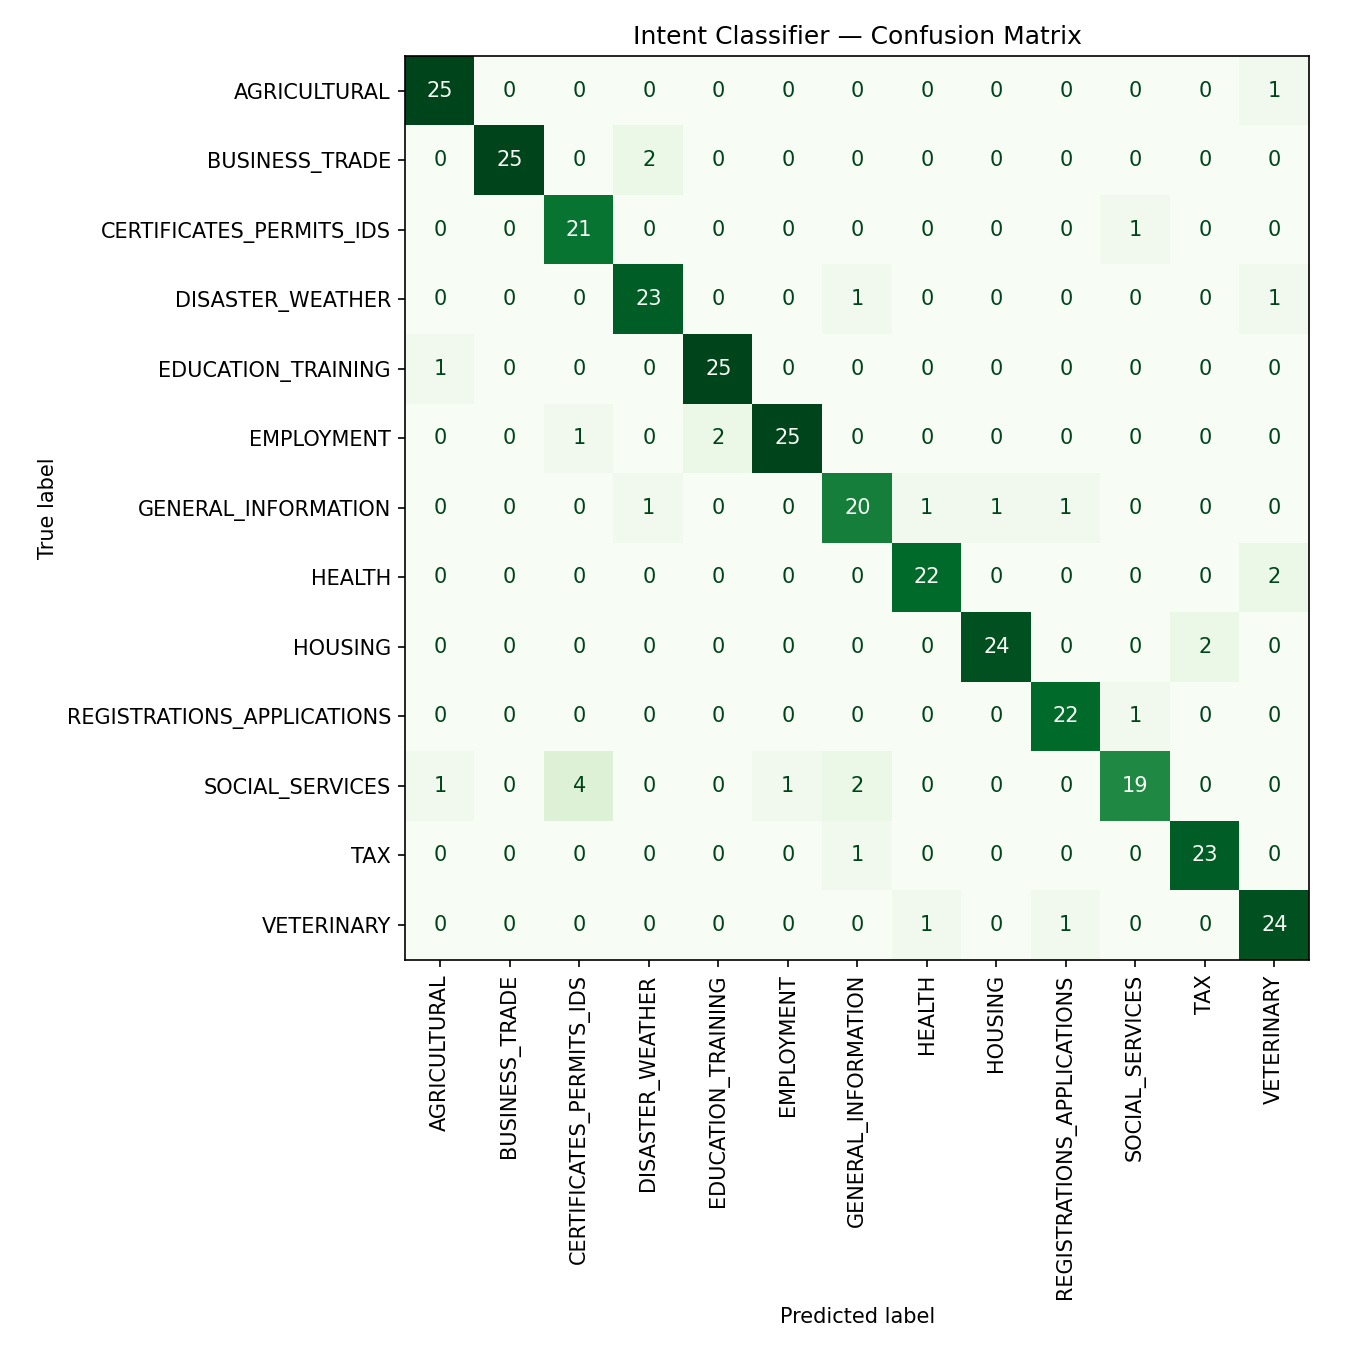

In [ ]:
from IPython.display import Image, display
display(Image("evaluation/confusion_matrix.png", width=1000, height=1000))

In [ ]:
NGROK_AUTHTOKEN = "3I7Ue1fdFKnjX9Glmm09ioLQew2_4XJr64JW2qC1vWZwdeqLV" # get ur own ngrok token to run this thingy

from pyngrok import ngrok
ngrok.set_auth_token(NGROK_AUTHTOKEN)

In [ ]:
from backend import rag_pipeline
print(rag_pipeline.__file__)

/content/calamba_chatbot/backend/rag_pipeline.py


In [ ]:
import threading
from backend.app import app
from pyngrok import ngrok
import time

def run_flask():
    app.run(host="0.0.0.0", port=5000)

flask_thread = threading.Thread(target=run_flask, daemon=True)
flask_thread.start()

time.sleep(2)
public_url = ngrok.connect(5000)
print("Your chatbot is live at:", public_url)

 * Serving Flask app 'backend.app'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://172.28.0.12:5000
INFO:werkzeug:Press CTRL+C to quit


Your chatbot is live at: NgrokTunnel: "https://cloak-wackiness-lapped.ngrok-free.dev" -> "http://localhost:5000"
